# Comparison of the performance between models trained with or without XIST promoter methylation

In [1]:
## conda : plot_python
import pandas as pd
import matplotlib.pyplot as plt
import glob 
import seaborn as sns
import numpy as np
from adjustText import adjust_text

plt.rcParams['svg.fonttype'] = 'none'
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'  # Keep text as text (not paths)

In [7]:
wo_xist_washu = pd.read_csv("/path/to/project/pooch/pooch_data/07.models_selection_using_fdr_balance_X_n46/washu/prediction/chrX.predict.out", sep ='\t' ,header = 0)
wo_xist_washu = wo_xist_washu[['Sample','PredictProb_Maternal-Paternal']]
wo_xist_washu.columns = ['Sample',"wo_xist"]
wo_xist_washu

,Sample,wo_xist
0,PAN010_ONT_Winnowmap2,0.832194
1,PAN010_PACBIO_Winnowmap2,0.995411
2,PAN027_ONT_Winnowmap2,0.456671
3,PAN027_PACBIO_Winnowmap2,0.991751
4,PAN028_ONT_Winnowmap2,0.814777
5,PAN028_PACBIO_Winnowmap2,0.995847


In [4]:
w_xist_washu = pd.read_csv("/path/to/project/pooch/pooch_data/07.models_selection_using_fdr_balance_X_n46_xist_slope_adjust/washu/chrX.predictions.tsv", sep ='\t', header = 0)
w_xist_washu = w_xist_washu[['Sample','PredictProb_Maternal-Paternal']]
w_xist_washu.columns = ['Sample',"w_xist"]

w_xist_washu

,Sample,w_xist
0,PAN010_ONT_Winnowmap2,0.957586
1,PAN010_PACBIO_Winnowmap2,0.999996
2,PAN027_ONT_Winnowmap2,0.683287
3,PAN027_PACBIO_Winnowmap2,0.999987
4,PAN028_ONT_Winnowmap2,0.995079
5,PAN028_PACBIO_Winnowmap2,0.999999


In [5]:
xist_washu = pd.read_csv("/path/to/project/pooch/test/washu-pedigree/methylation_analysis/chrX_promoter_methylation_washu.tsv", sep = '\t', header = 0 )
xist_washu

,Sample,XIST_diff
0,PAN010_ONT_Winnowmap2,-0.416279
1,PAN010_PACBIO_Winnowmap2,0.538318
2,PAN027_ONT_Winnowmap2,-0.671629
3,PAN027_PACBIO_Winnowmap2,-0.816864
4,PAN028_ONT_Winnowmap2,-0.252873
5,PAN028_PACBIO_Winnowmap2,0.241270


In [12]:
df_washu = pd.merge(pd.merge(wo_xist_washu, w_xist_washu, on ="Sample"), xist_washu, on = "Sample")
df_washu['improve'] = df_washu['w_xist'] - df_washu['wo_xist']
df_washu['sample_name'] = df_washu['Sample'].str.split("_").str[0]
df_washu['platform'] = df_washu['Sample'].str.split("_").str[1]
df_washu

,Sample,wo_xist,w_xist,XIST_diff,improve,sample_name,platform
0,PAN010_ONT_Winnowmap2,0.832194,0.957586,-0.416279,0.125392,PAN010,ONT
1,PAN010_PACBIO_Winnowmap2,0.995411,0.999996,0.538318,0.004585,PAN010,PACBIO
2,PAN027_ONT_Winnowmap2,0.456671,0.683287,-0.671629,0.226616,PAN027,ONT
3,PAN027_PACBIO_Winnowmap2,0.991751,0.999987,-0.816864,0.008236,PAN027,PACBIO
4,PAN028_ONT_Winnowmap2,0.814777,0.995079,-0.252873,0.180302,PAN028,ONT
5,PAN028_PACBIO_Winnowmap2,0.995847,0.999999,0.241270,0.004152,PAN028,PACBIO


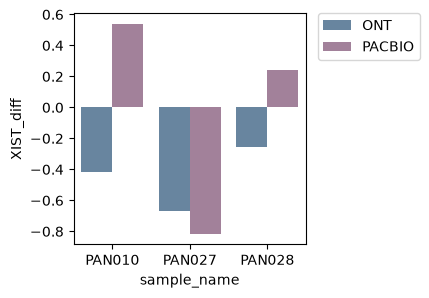

In [17]:
platform_colors = {
    "PACBIO" : '#A77B9D',  # PacBio
    "ONT": '#5F86A8',  # ONT
}

plt.figure(figsize = (3,3))
sns.barplot(df_washu, x = "sample_name", y = "XIST_diff", hue= "platform", palette=platform_colors)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", borderaxespad=0)
plt.savefig("/path/to/project/pooch/figures/washu_xist_by_probability3.pdf")
plt.show()

In [20]:
df_melt_washu = pd.melt(
    df_washu,
    id_vars=['Sample','platform','sample_name','XIST_diff'],
    #value_vars=,
    var_name="mode",
    value_name="prob",
    #col_level=None,
    #ignore_index=True,
)
df_melt_washu['hue'] = df_melt_washu['platform'] + df_melt_washu['mode'] 
df_melt_washu.head(2)

,Sample,platform,sample_name,XIST_diff,mode,prob,hue
0,PAN010_ONT_Winnowmap2,ONT,PAN010,-0.416279,wo_xist,0.832194,ONTwo_xist
1,PAN010_PACBIO_Winnowmap2,PACBIO,PAN010,0.538318,wo_xist,0.995411,PACBIOwo_xist


/tmp/ipykernel_388195/1566391195.py:101: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


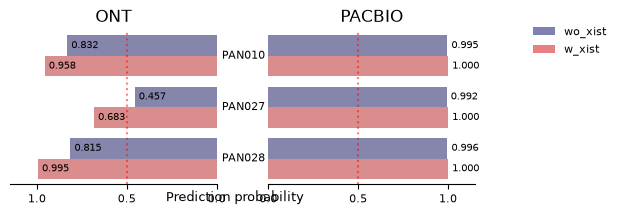

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

plot_df = df_melt_washu.loc[
    (df_melt_washu["platform"].isin(["ONT", "PACBIO"])) &
    (df_melt_washu["mode"] != "improve")
].copy()

sample_order = plot_df["sample_name"].drop_duplicates().tolist()
mode_order = ["wo_xist", "w_xist"]

palette = {
    "wo_xist": "#8080b2",
    "w_xist": "#e78080"
}

fig, axes = plt.subplots(
    1, 2,
    figsize=(6, 2),
    sharey=True,
    gridspec_kw={"wspace": 0.25}
)

for ax, platform in zip(axes, ["ONT", "PACBIO"]):

    sub = plot_df.loc[plot_df["platform"] == platform]

    sns.barplot(
        data=sub,
        x="prob",
        y="sample_name",
        hue="mode",
        order=sample_order,
        hue_order=mode_order,
        palette=palette,
        orient="h",
        errorbar=None,
        ax=ax
    )

    ax.set_xlim(0, 1.15)
    ax.set_title(platform)
    ax.set_xlabel("")
    ax.set_ylabel("")

    # Add actual probability at the end of each bar
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.3f",
            label_type="edge",
            padding=3,
            fontsize=7
        )

    if ax.legend_:
        ax.legend_.remove()

# Flip ONT axis
axes[0].invert_xaxis()

axes[0].axvline( x = 0.5, color = "red", linestyle= ":", alpha = .5,)
axes[1].axvline( x = 0.5, color = "red", linestyle= ":", alpha = .5)

# Sample labels between panels
for i, sample in enumerate(sample_order):
    axes[1].text(
        -0.12,
        i,
        sample,
        transform=axes[1].get_yaxis_transform(),
        ha="center",
        va="center",
        fontsize=8
    )

for ax in axes:
    ax.tick_params(axis="y", labelleft=False, left=False)
    ax.set_xticks([0, 0.5, 1])
    ax.tick_params(axis="x", labelsize=8)

fig.supxlabel("Prediction probability", fontsize=9)

legend_elements = [
    Patch(facecolor=palette[m], label=m)
    for m in mode_order
]

fig.legend(
    handles=legend_elements,
    loc="upper left",
    bbox_to_anchor=(0.98, 0.95),
    frameon=False,
    fontsize=8
)

sns.despine(left=True)
plt.tight_layout()
plt.savefig("/path/to/project/pooch/figures/washu_xist_by_probability2.pdf")
plt.show()

/tmp/ipykernel_388195/63192451.py:139: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


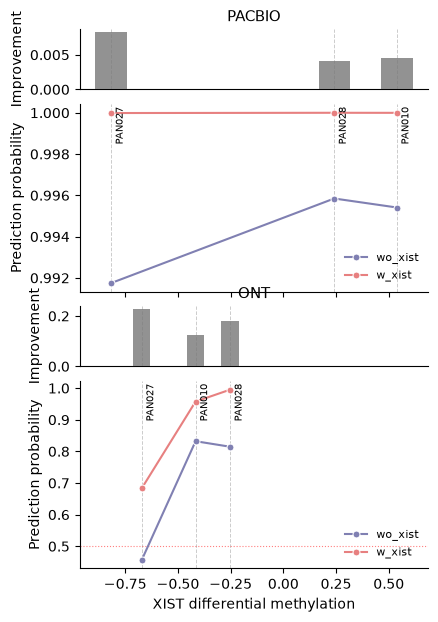

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Illustrator editable text
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["svg.fonttype"] = "none"

palette = {
    "wo_xist": "#8080b2",
    "w_xist": "#e78080"
}

platform_order = ["PACBIO", "ONT"]

fig, axes = plt.subplots(
    4, 1,
    figsize=(4.5, 7),
    sharex=True,
    gridspec_kw={
        "height_ratios": [.8, 2.5, .8, 2.5],
        "hspace": 0.12
    }
)

for i, platform in enumerate(platform_order):

    ax_bar = axes[i * 2]
    ax_line = axes[i * 2 + 1]

    sub = df_washu.loc[
        df_washu["platform"] == platform
    ].sort_values("XIST_diff").copy()

    # ----------------------------------
    # 1. Improvement barplot
    # ----------------------------------

    x = sub["XIST_diff"].to_numpy()
    improvement = sub["improve"].to_numpy()

    # Bar width based on XIST_diff spacing
    unique_x = np.sort(np.unique(x))
    if len(unique_x) > 1:
        bar_width = np.min(np.diff(unique_x)) * 0.5
    else:
        bar_width = 0.1

    ax_bar.bar(
        x,
        improvement,
        width=bar_width,
        color="#777777",
        alpha=0.8,
        zorder=3
    )

    ax_bar.axhline(
        0,
        color="black",
        linewidth=0.7
    )

    ax_bar.set_ylabel("Improvement")
    ax_bar.set_title(platform, fontsize=11)
    ax_bar.grid(False)

    # ----------------------------------
    # 2. Prediction probability lineplot
    # ----------------------------------

    for col in ["wo_xist", "w_xist"]:

        sns.lineplot(
            data=sub,
            x="XIST_diff",
            y=col,
            marker="o",
            markersize=5,
            linewidth=1.5,
            color=palette[col],
            label=col,
            estimator=None,
            ax=ax_line
        )

    # Sample-specific vertical lines
    for _, row in sub.iterrows():

        xpos = row["XIST_diff"]

        for ax in [ax_bar, ax_line]:
            ax.axvline(
                x=xpos,
                color="gray",
                linestyle="--",
                linewidth=0.7,
                alpha=0.4,
                zorder=0
            )

        # Sample labels
        ax_line.annotate(
            row["sample_name"],
            xy=(xpos, 0.985),
            xycoords=("data", "axes fraction"),
            xytext=(3, 0),
            textcoords="offset points",
            rotation=90,
            ha="left",
            va="top",
            fontsize=7,
            color="black"
        )

    ax_line.set_ylabel("Prediction probability")
    ax_line.set_xlabel("")
    ax_line.grid(False)

    ax_line.legend(
        frameon=False,
        fontsize=8,
        loc="lower right"
    )

    # Hide x-axis labels except bottom panel
    ax_bar.tick_params(axis="x", bottom=False, labelbottom=False)

axes[-1].set_xlabel("XIST differential methylation")
axes[-1].axhline(
        y=0.5,
        color="red",
        linestyle=":",
        alpha=0.5,
        linewidth=0.8,
        zorder=0
    )
sns.despine()
plt.tight_layout()

plt.savefig(
    "XIST_prediction_by_platform_with_improvement.pdf",
    dpi=600,
    bbox_inches="tight"
)
plt.savefig("/path/to/project/pooch/figures/washu_xist_by_probability.pdf")
plt.show()

## Using HPRC

In [33]:
swap_samples  = ["HG03579", "HG02717", "HG02451"]
# only HG02451 is female

In [ ]:
# this dataset have flipped value for swap sample
wo_xist_hprc = pd.read_csv("/path/to/project/pooch/pooch_data/07.models_selection_using_fdr_balance_X_n46/hprc/chrX.figure3.predict.out", sep ='\t', header = 0)
wo_xist_hprc = wo_xist_hprc[['Sample','PredictProb_Maternal-Paternal']]
wo_xist_hprc.loc[wo_xist_hprc['Sample'].isin(swap_samples), "PredictProb_Maternal-Paternal"] = 1- wo_xist_hprc.loc[wo_xist_hprc['Sample'].isin(swap_samples), "PredictProb_Maternal-Paternal"]
wo_xist_hprc.columns = ['Sample',"wo_xist"]
wo_xist_hprc

wo_xist_hprc.head(2)

,Sample,wo_xist
0,HG00408,0.930311
1,HG00423,0.964150


In [ ]:
# this dataset have fixed value for swap sample
w_xist_hprc = pd.read_csv("/path/to/project/pooch/pooch_data/07.models_selection_using_fdr_balance_X_n46_xist_slope_adjust/chrX.slope_adjusted.test.predictions.fixed_swap_sample.tsv", sep ='\t' , header = 0)
w_xist_hprc = w_xist_hprc.loc[w_xist_hprc['y_true'] == 1]
w_xist_hprc = w_xist_hprc[['Sample','p_right_paternal']]
w_xist_hprc.columns = ['Sample',"w_xist"]
w_xist_hprc.head(2)

,Sample,w_xist
0,HG01081,0.999989
1,HG01960,0.994123


In [36]:
# this dataset have fixed value for swap sample
xist_hprc = pd.read_csv("/path/to/project/pooch/pooch_data/07.models_selection_using_fdr_balance_X_n46_xist_covar/xist_level.tsv", sep = '\t', header=0)
xist_hprc.columns = ['Sample',"XIST_diff"]
xist_hprc.head(2)

,Sample,XIST_diff
0,HG00408,0.172347
1,HG00423,-0.132071


In [40]:
df_hprc = pd.merge(pd.merge(wo_xist_hprc, w_xist_hprc, on ="Sample"), xist_hprc, on = "Sample")
df_hprc['improve'] = df_hprc['w_xist'] - df_hprc['wo_xist']
df_hprc.head(2)

,Sample,wo_xist,w_xist,XIST_diff,improve
0,HG01081,0.994850,0.999989,0.380255,0.005139
1,HG01960,0.866892,0.994123,0.661340,0.127231


In [41]:
from scipy import stats


x = df_hprc['improve']
y = df_hprc['XIST_diff']

r, p_val = stats.pearsonr(x, y)

# Alternatives for non-linear or ranked data
rho, p_val_s = stats.spearmanr(x, y)
tau, p_val_k = stats.kendalltau(x, y)

print(f"r: {r}, p : {p_val}")
print(f"rho: {rho}, p : {p_val_s}")
print(f"tau: {tau}, p : {p_val_k}")

r: 0.024475385143391155, p : 0.9367414983433301
rho: -0.06043956043956044, p : 0.8445023706449681
tau: -0.025641025641025637, p : 0.9523619079608663


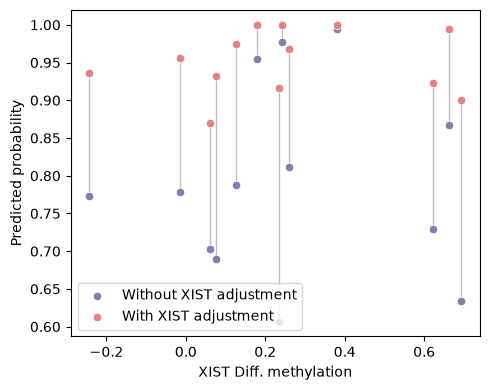

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

palette = {
    "wo_xist": "#8080b2",
    "w_xist": "#e78080",
}

plot_df = df_hprc.dropna(subset=["XIST_diff", "wo_xist", "w_xist"])

fig, ax = plt.subplots(figsize=(5, 4))

ax.vlines(
    x=plot_df["XIST_diff"],
    ymin=plot_df[["wo_xist", "w_xist"]].min(axis=1),
    ymax=plot_df[["wo_xist", "w_xist"]].max(axis=1),
    color="gray",
    alpha=0.5,
    linewidth=1,
    zorder=1,
)

sns.scatterplot(
    data=plot_df,
    x="XIST_diff",
    y="wo_xist",
    color=palette["wo_xist"],
    label="Without XIST adjustment",
    ax=ax,
    zorder=2,
)

sns.scatterplot(
    data=plot_df,
    x="XIST_diff",
    y="w_xist",
    color=palette["w_xist"],
    label="With XIST adjustment",
    ax=ax,
    zorder=2,
)

ax.set_xlabel("XIST Diff. methylation")
ax.set_ylabel("Predicted probability")

plt.tight_layout()
plt.savefig("/path/to/project/pooch/figures/washu_xist_by_probability4.pdf")
plt.show()